## Thêm các thư viện cần thiết

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df=pd.read_excel(r'D:\DOAN\machine_learning\lab05\data\Online_Retail.xlsx')

FileNotFoundError: [Errno 2] No such file or directory: 'D:\\DOAN\\machine_learning\\lab05\\data\\Online_Retail.xlsx'

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [5]:
df.shape

(541909, 8)

* nhiều dữ liệu bị mất ở CustomerID

In [6]:
cols=['CustomerID']
def ismissing(cols, df: pd.DataFrame):
    for col in cols:
        missingcount = df[col].isnull().sum()
        totalcount = len(df[col])
        missingper = missingcount / totalcount * 100

        print(f"{col}:")
        print(f"  Missing count: {missingcount}")
        print(f"  Missing percentage: {missingper:.2f}%")

In [7]:
ismissing(cols,df)

CustomerID:
  Missing count: 135080
  Missing percentage: 24.93%


* Cột CustomerID có khoảng 24.93% giá trị bị thiếu. Cần xem xét mối quan hệ giữa cột này và biến mục tiêu (target) cũng như các đặc trưng khác để đánh giá giá trị sử dụng của nó.

* Tuy nhiên, CustomerID chủ yếu là biến định danh, dùng để phân biệt khách hàng, không trực tiếp phản ánh đặc điểm hay hành vi của khách hàng. Vì vậy, nếu không có bằng chứng cho thấy mã khách hàng mang thông tin hữu ích cho mô hình, nên cân nhắc loại bỏ cột này.

* Nếu CustomerID có vai trò quan trọng trong việc liên kết dữ liệu từ nhiều bảng hoặc xác định các giao dịch của cùng một khách hàng, cần giữ lại trong dữ liệu gốc để phục vụ các bước xử lý tiếp theo.

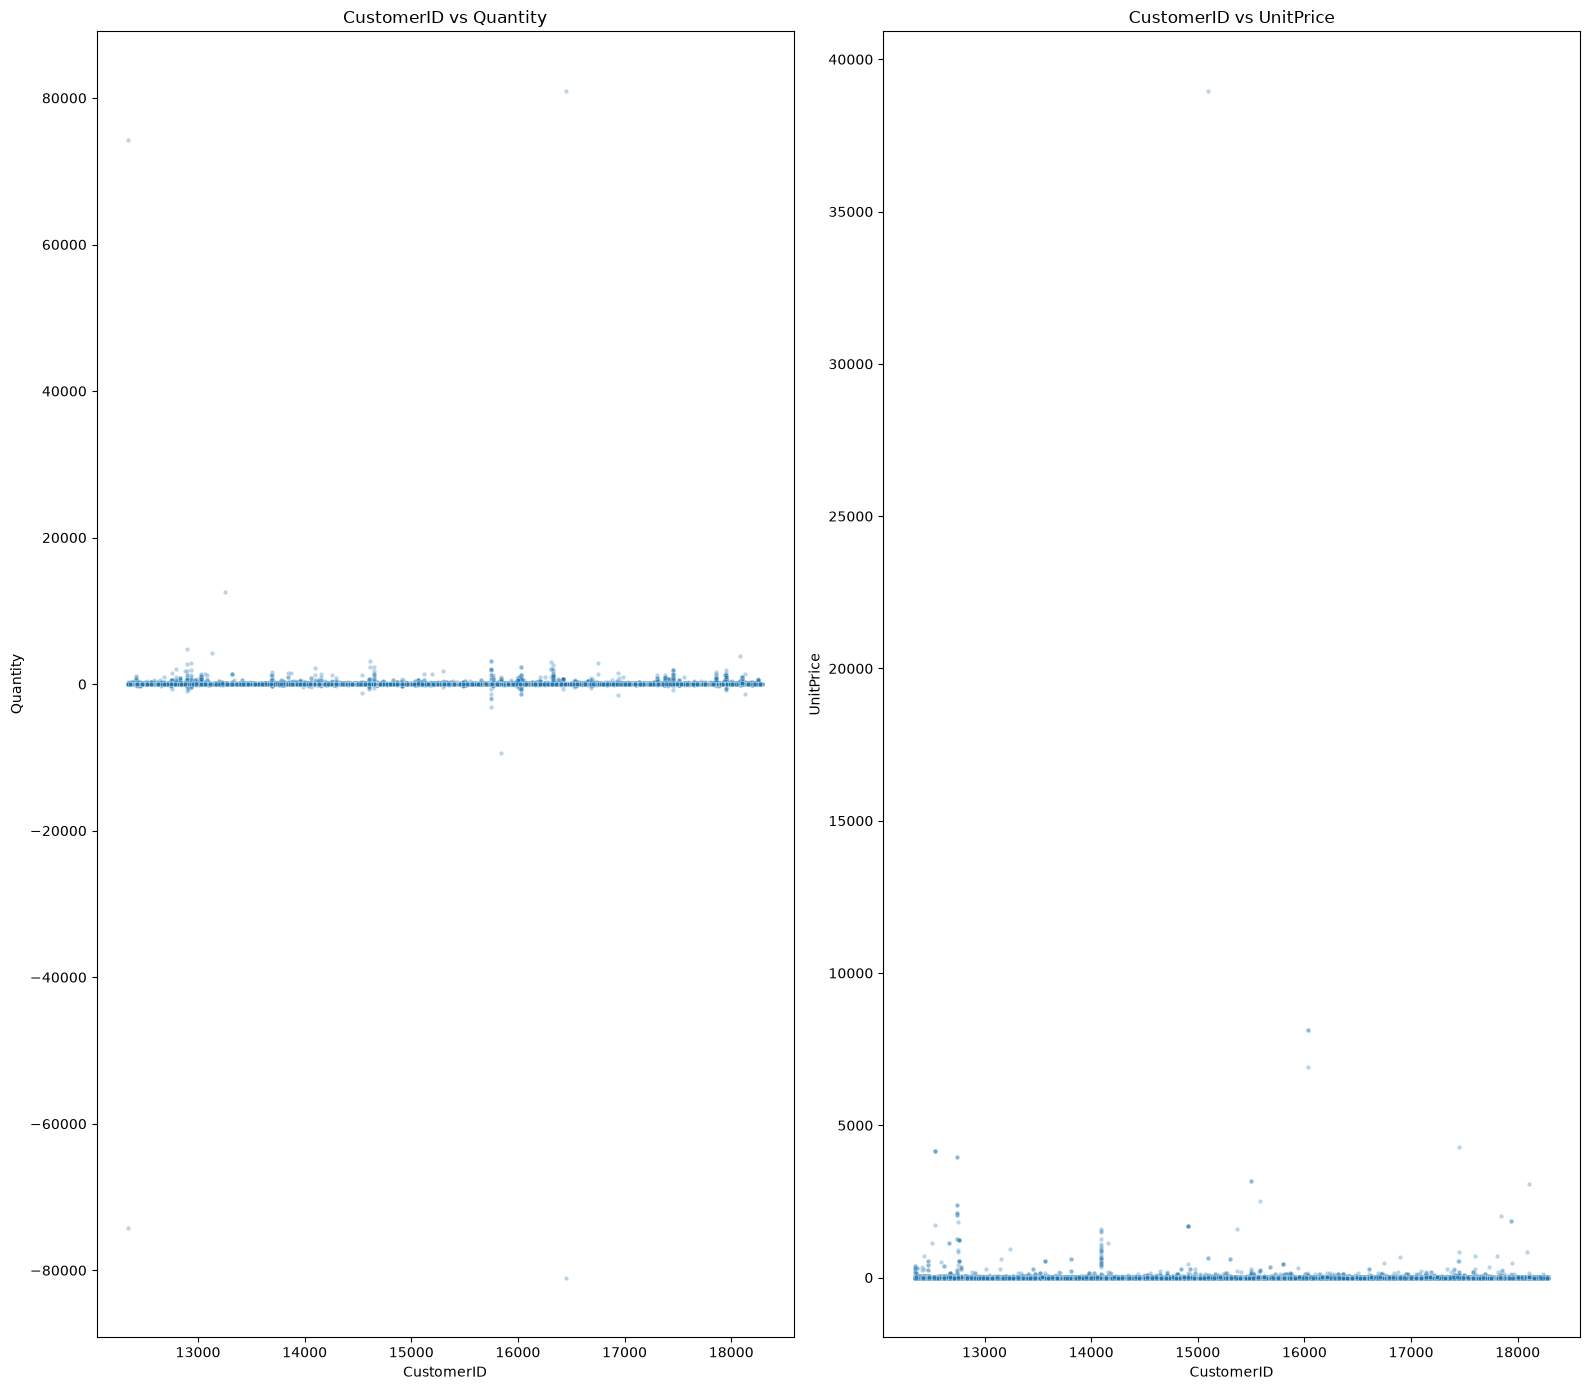

In [8]:
# cols=df.select_dtypes(include='number').columns.to_list()
# sns.histplot(data=df,x='CustomerID',hue='Country')

cols = ['Quantity', 'UnitPrice']
fig,axes=plt.subplots(1,2,figsize=(16,4*3.5))
for ax,col in zip(axes,cols):
    sns.scatterplot(
        data=df,
        x='CustomerID',
        y=col,
        alpha=0.3,
        s=10,
        ax=ax
    )
    ax.set_title(f'CustomerID vs {col}')

plt.tight_layout()
plt.show()

In [9]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


## Kiểm tra các cột còn lại

In [10]:
ismissing(['Description'],df)

Description:
  Missing count: 1454
  Missing percentage: 0.27%


In [11]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

* Description chỉ thiếu 1454 dòng (khoảng 0.27%), rất ít nên có thể loại bỏ hoặc điền 'Unknown' mà không ảnh hưởng nhiều.

* CustomerID thiếu nhiều nhất (24.93%), các cột còn lại gần như đầy đủ.

## Dữ liệu trùng lặp

In [12]:
print(f'Số dòng trùng lặp: {df.duplicated().sum()}')
df[df.duplicated(keep=False)].sort_values(['InvoiceNo','StockCode']).head(10)

Số dòng trùng lặp: 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


* Có các dòng trùng lặp hoàn toàn ở tất cả các cột, nhiều khả năng là lỗi ghi nhận trùng nên sẽ loại bỏ ở bước làm sạch.

## Đơn hủy và giá trị bất thường

In [13]:
is_cancel = df['InvoiceNo'].astype(str).str.startswith('C')

print(f'Số dòng thuộc đơn hủy (InvoiceNo bắt đầu bằng C): {is_cancel.sum()}')
print(f'Số dòng có Quantity < 0: {(df["Quantity"] < 0).sum()}')
print(f'Số dòng có Quantity < 0 nhưng không phải đơn hủy: {((df["Quantity"] < 0) & ~is_cancel).sum()}')
print(f'Số dòng có UnitPrice <= 0: {(df["UnitPrice"] <= 0).sum()}')

Số dòng thuộc đơn hủy (InvoiceNo bắt đầu bằng C): 9288
Số dòng có Quantity < 0: 10624
Số dòng có Quantity < 0 nhưng không phải đơn hủy: 1336
Số dòng có UnitPrice <= 0: 2517


In [14]:
df[df['UnitPrice'] <= 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [15]:
df[df['Quantity'] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


* Quantity âm chủ yếu nằm trong các đơn hủy (InvoiceNo bắt đầu bằng 'C'). Đây là giao dịch trả hàng/hủy đơn, không phải bán hàng.

* Một số dòng Quantity âm không phải đơn hủy và các dòng UnitPrice = 0 (Description thường bị trống) có thể là điều chỉnh kho, hàng hỏng hoặc tặng, không phản ánh doanh thu thực.

* UnitPrice có giá trị âm rất lớn (min = -11062.06) nên có thể là dòng điều chỉnh nợ xấu chứ không phải giao dịch bán hàng.

* Với mục tiêu phân tích doanh thu, sẽ loại các dòng này ở bước làm sạch.

## Làm sạch dữ liệu

In [16]:
df_clean = df.drop_duplicates()
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)].copy()

# Doanh thu của từng dòng
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['UnitPrice']

print(df.shape, '->', df_clean.shape)

(541909, 8) -> (524878, 9)


* Giữ lại các dòng thiếu CustomerID vì các phân tích theo quốc gia, sản phẩm, thời gian bên dưới không cần mã khách hàng.

* Chỉ cần loại các dòng này khi phân tích theo từng khách hàng (ví dụ: top khách hàng, phân cụm khách hàng).

## Phân tích đơn biến

In [17]:
df_clean[['Quantity','UnitPrice','Revenue']].describe()

,Quantity,UnitPrice,Revenue
count,524878.000000,524878.000000,524878.000000
mean,10.616600,3.922573,20.275399
std,156.280031,36.093028,271.693566
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,3.900000
50%,4.000000,2.080000,9.920000
75%,11.000000,4.130000,17.700000
max,80995.000000,13541.330000,168469.600000


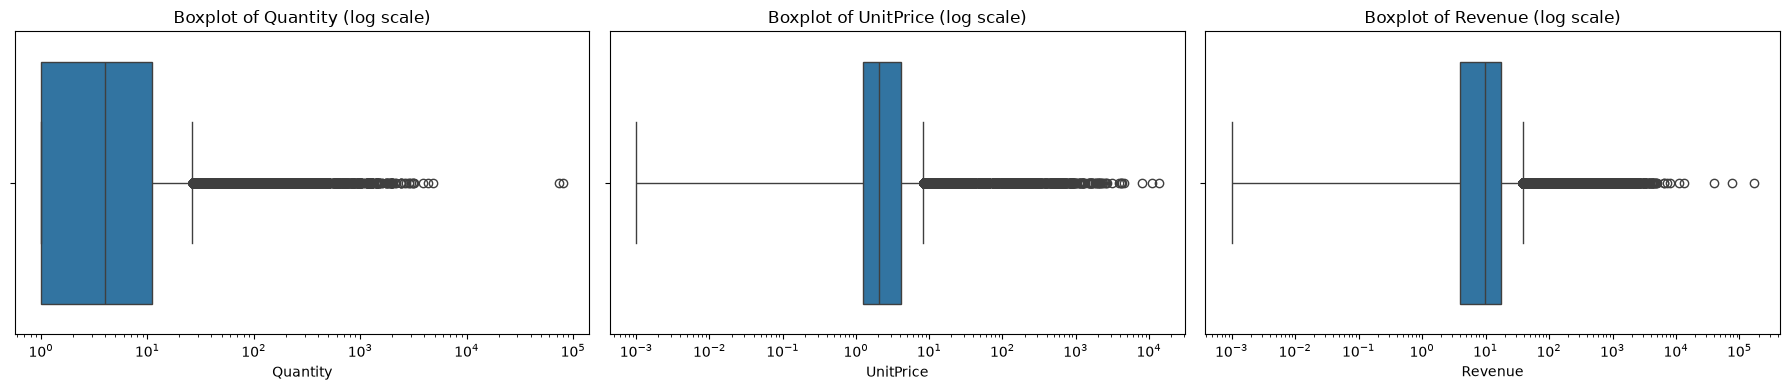

In [18]:
cols = ['Quantity', 'UnitPrice', 'Revenue']
fig,axes=plt.subplots(1,3,figsize=(18,4))
for ax,col in zip(axes,cols):
    sns.boxplot(data=df_clean, x=col, ax=ax)
    ax.set_xscale('log')
    ax.set_title(f'Boxplot of {col} (log scale)')

plt.tight_layout()
plt.show()

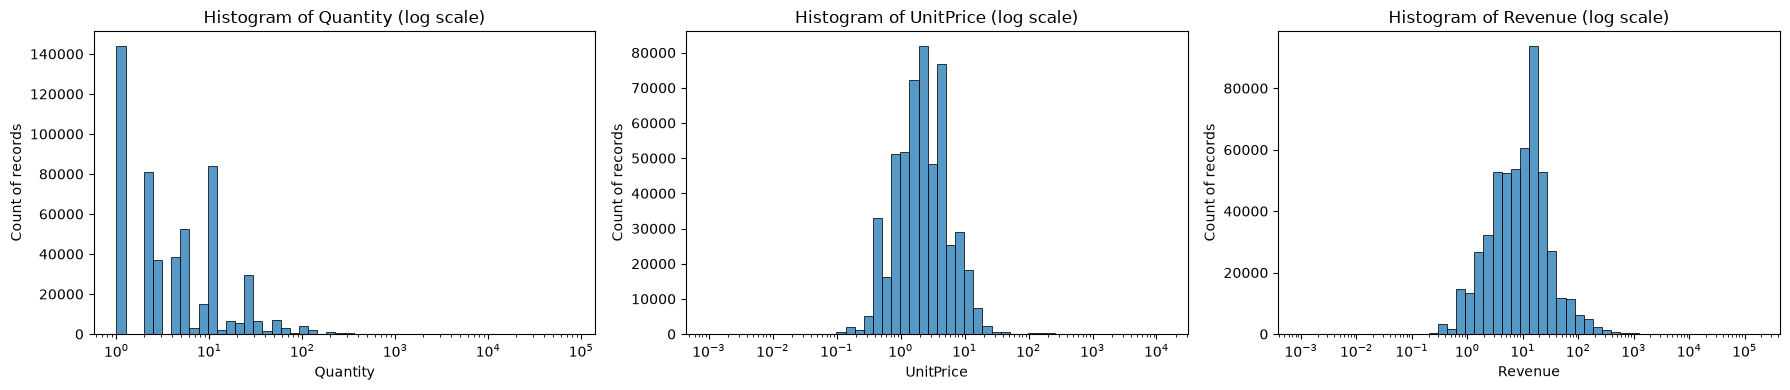

In [19]:
fig,axes=plt.subplots(1,3,figsize=(18,4))
for ax,col in zip(axes,cols):
    sns.histplot(data=df_clean, x=col, bins=50, log_scale=True, ax=ax)
    ax.set_title(f'Histogram of {col} (log scale)')
    ax.set_ylabel('Count of records')

plt.tight_layout()
plt.show()

* Cả 3 biến đều lệch phải mạnh, trung bình lớn hơn nhiều so với trung vị và có rất nhiều ngoại lai (phải dùng thang log mới nhìn rõ được biểu đồ).

* Phần lớn dòng hàng có Quantity nhỏ và UnitPrice thấp, chỉ một số ít giao dịch bán sỉ với số lượng rất lớn.

* Khi mô tả dữ liệu nên dùng trung vị (median) thay cho trung bình, và cân nhắc xử lý ngoại lai hoặc biến đổi log nếu dùng cho mô hình.

## Phân tích theo quốc gia

In [20]:
country_revenue = df_clean.groupby('Country')['Revenue'].sum().sort_values(ascending=False).reset_index()

print((df_clean['Country'].value_counts(normalize=True).head(5) * 100).round(2))

Country
United Kingdom    91.45
Germany            1.72
France             1.60
EIRE               1.50
Spain              0.47
Name: proportion, dtype: float64


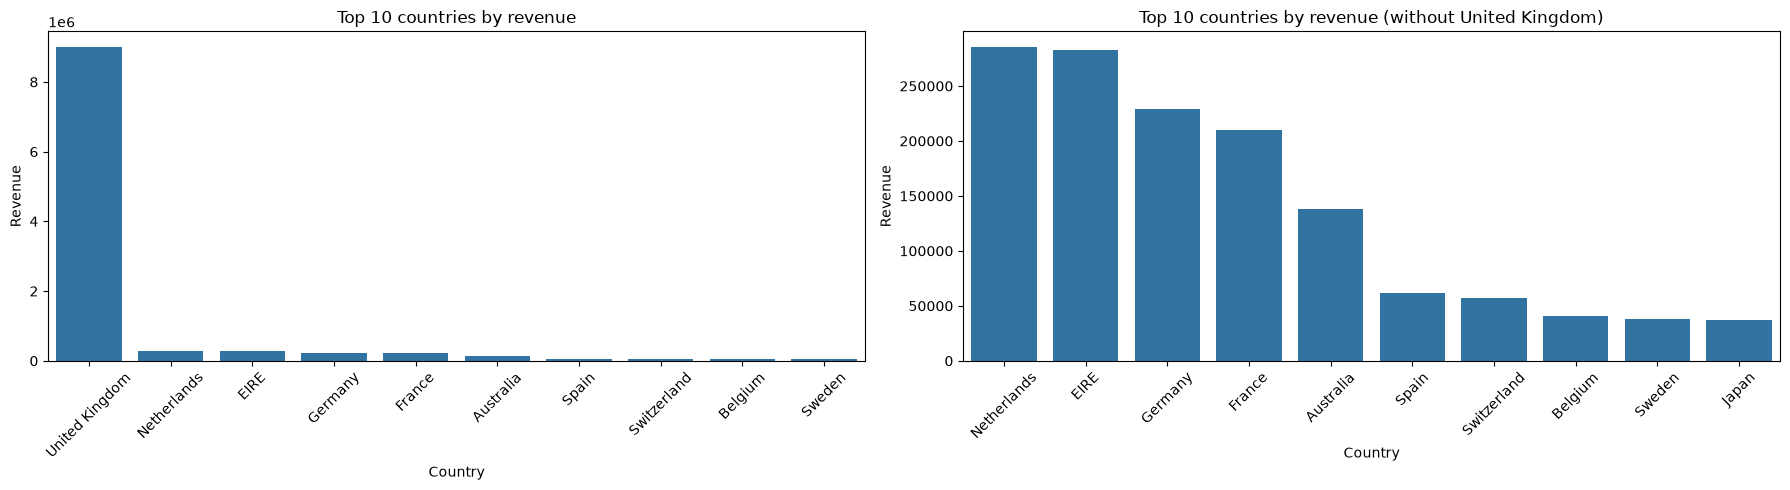

In [21]:
fig,axes=plt.subplots(1,2,figsize=(18,5))

top10 = country_revenue.head(10)
sns.barplot(data=top10, x='Country', y='Revenue', ax=axes[0])
axes[0].set_title('Top 10 countries by revenue')
axes[0].tick_params(axis='x', rotation=45)

top10_no_uk = country_revenue[country_revenue['Country'] != 'United Kingdom'].head(10)
sns.barplot(data=top10_no_uk, x='Country', y='Revenue', ax=axes[1])
axes[1].set_title('Top 10 countries by revenue (without United Kingdom)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

* United Kingdom chiếm gần như toàn bộ số dòng và doanh thu, các quốc gia khác rất nhỏ so với UK nên phải bỏ UK ra mới so sánh được các thị trường còn lại.

* Dữ liệu mất cân bằng theo quốc gia rất nặng, nếu xây mô hình theo Country cần lưu ý điểm này.

## Phân tích theo sản phẩm

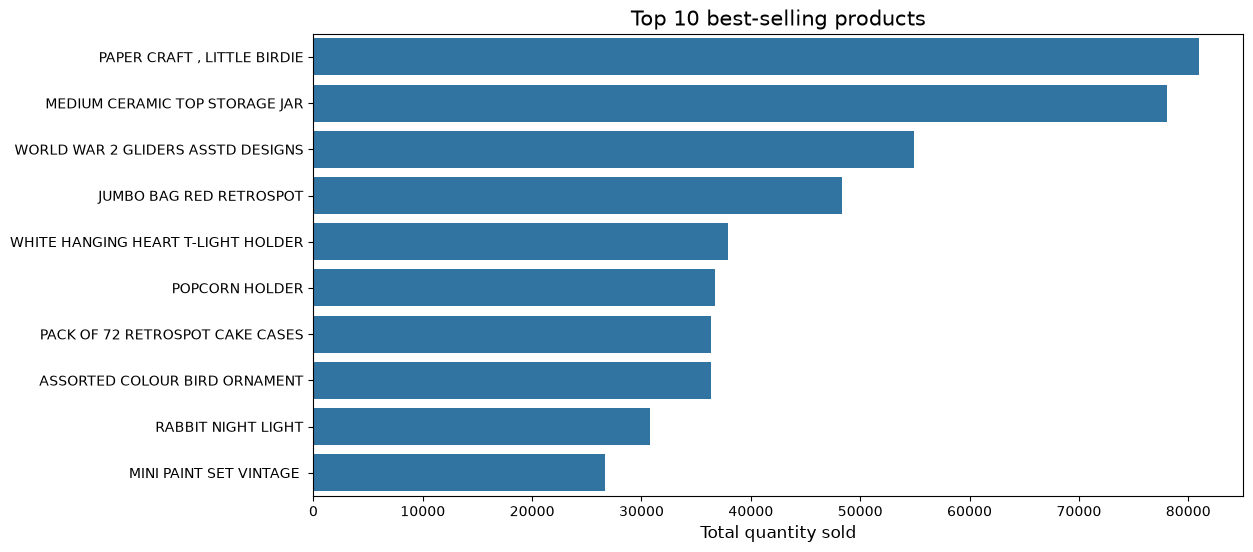

In [22]:
top_products = df_clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(12,6))
ax = sns.barplot(data=top_products, x='Quantity', y='Description')
ax.set_xlabel('Total quantity sold', fontsize=12)
ax.set_ylabel('')
ax.set_title('Top 10 best-selling products', fontsize=15)
plt.show()

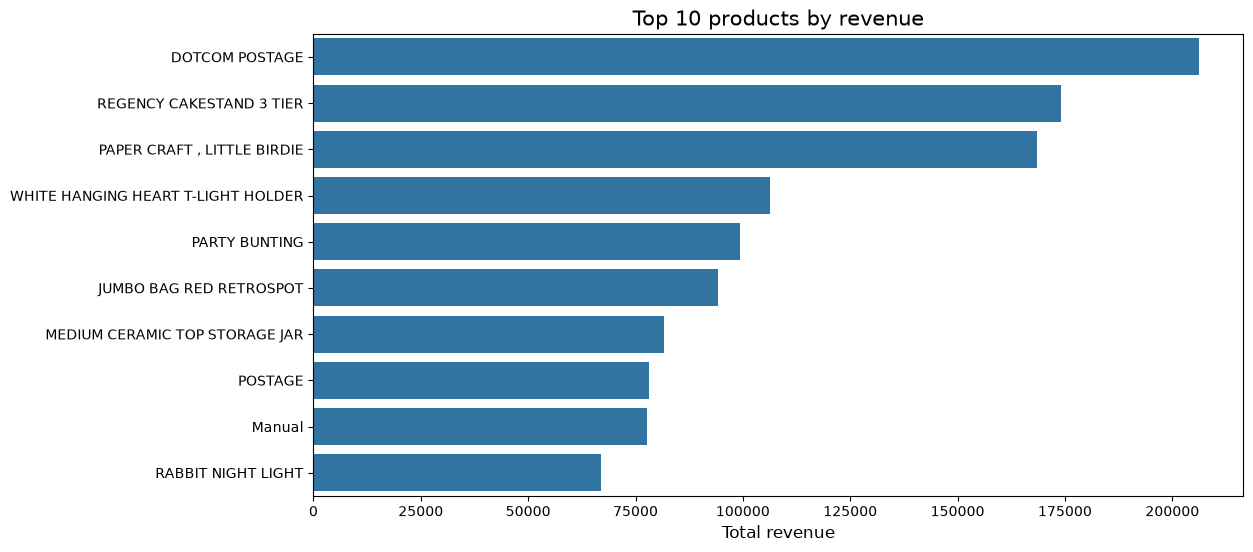

In [23]:
top_products_revenue = df_clean.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(12,6))
ax = sns.barplot(data=top_products_revenue, x='Revenue', y='Description')
ax.set_xlabel('Total revenue', fontsize=12)
ax.set_ylabel('')
ax.set_title('Top 10 products by revenue', fontsize=15)
plt.show()

* Top sản phẩm theo số lượng và theo doanh thu không trùng hoàn toàn: có sản phẩm giá rẻ bán rất nhiều và sản phẩm giá cao bán ít hơn nhưng doanh thu lớn.

## Phân tích theo thời gian

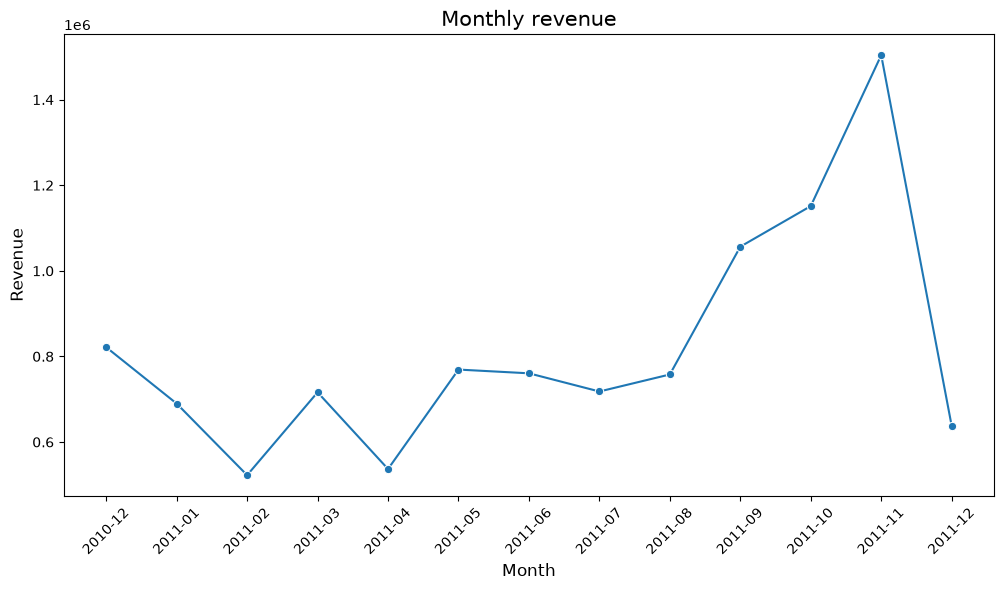

In [24]:
df_clean['Month'] = df_clean['InvoiceDate'].dt.to_period('M').astype(str)
df_clean['Weekday'] = df_clean['InvoiceDate'].dt.day_name()
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour

monthly = df_clean.groupby('Month')['Revenue'].sum().reset_index()

plt.figure(figsize=(12,6))
ax = sns.lineplot(data=monthly, x='Month', y='Revenue', marker='o')
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Revenue', fontsize=12)
ax.set_title('Monthly revenue', fontsize=15)
plt.xticks(rotation=45)
plt.show()

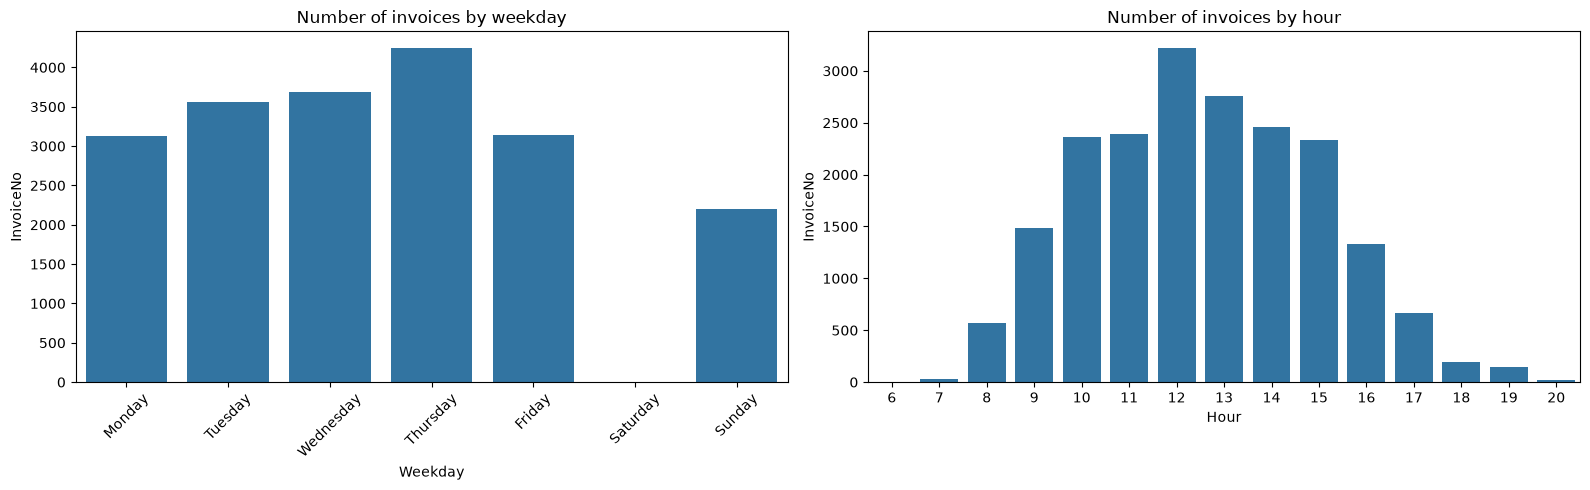

In [25]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekday = df_clean.groupby('Weekday')['InvoiceNo'].nunique().reindex(order).fillna(0).reset_index()
hour = df_clean.groupby('Hour')['InvoiceNo'].nunique().reset_index()

fig,axes=plt.subplots(1,2,figsize=(16,5))
sns.barplot(data=weekday, x='Weekday', y='InvoiceNo', ax=axes[0])
axes[0].set_title('Number of invoices by weekday')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(data=hour, x='Hour', y='InvoiceNo', ax=axes[1])
axes[1].set_title('Number of invoices by hour')

plt.tight_layout()
plt.show()

* Dữ liệu chỉ trải từ 01/12/2010 đến 09/12/2011 (theo describe ở trên), nên tháng 12/2011 mới có vài ngày và doanh thu thấp là do thiếu dữ liệu, không phải do bán kém.

* Doanh thu có xu hướng tăng mạnh vào các tháng cuối năm (mùa mua sắm lễ).

* Số hóa đơn tập trung vào giờ làm việc ban ngày, cao nhất quanh giữa trưa, gần như không có giao dịch ban đêm.

* Theo ngày trong tuần, có ngày không có giao dịch nào (thường là thứ Bảy), đây là đặc điểm của tập dữ liệu.

## Phân tích hai biến

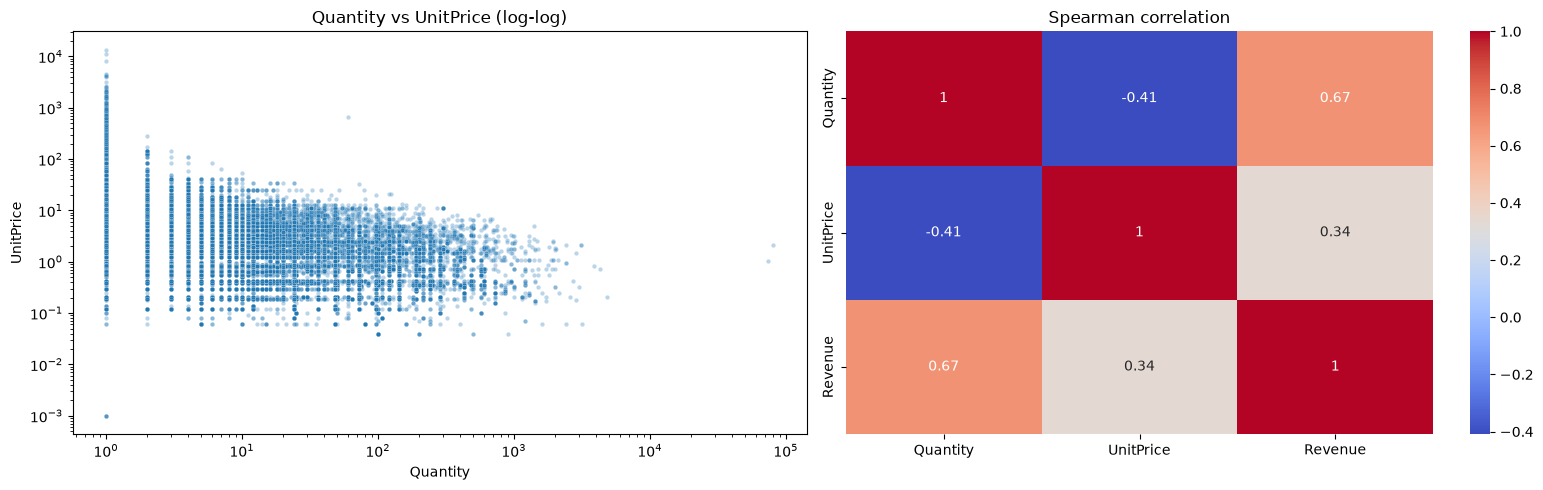

In [26]:
fig,axes=plt.subplots(1,2,figsize=(16,5))

sns.scatterplot(data=df_clean, x='Quantity', y='UnitPrice', alpha=0.3, s=10, ax=axes[0])
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_title('Quantity vs UnitPrice (log-log)')

sns.heatmap(df_clean[['Quantity','UnitPrice','Revenue']].corr(method='spearman'), annot=True, cmap='coolwarm', ax=axes[1])
axes[1].set_title('Spearman correlation')

plt.tight_layout()
plt.show()

In [27]:
pd.pivot_table(df_clean, values='Revenue', index='Country',
               aggfunc=['sum','mean','count']).sort_values(('sum','Revenue'), ascending=False).head(10)

,sum,mean,count
,Revenue,Revenue,Revenue
Country,,,
United Kingdom,9001744.094,18.754220,479985
Netherlands,285446.340,121.003111,2359
EIRE,283140.520,35.936098,7879
Germany,228678.400,25.338327,9025
France,209625.370,24.979191,8392
Australia,138453.810,117.234386,1181
Spain,61558.560,24.832013,2479
Switzerland,57067.600,29.145863,1958


* Dùng tương quan Spearman thay cho Pearson vì dữ liệu lệch mạnh và có nhiều ngoại lai.

* Quantity và UnitPrice có tương quan nghịch nhẹ: hàng giá thấp thường được mua với số lượng lớn hơn. Revenue tương quan dương với Quantity (do Revenue = Quantity x UnitPrice).

* Bảng pivot cho thấy UK vượt trội về tổng doanh thu, trong khi doanh thu trung bình mỗi dòng của một số nước nhỏ có thể cao hơn (khách mua sỉ).

## Nhận xét chung

* Dữ liệu gồm 541909 dòng, 8 cột. Cột CustomerID thiếu 24.93%, Description thiếu khoảng 0.27%.

* Chất lượng dữ liệu cần xử lý: dòng trùng lặp, đơn hủy (Quantity âm), UnitPrice bằng 0 hoặc âm. Sau khi làm sạch còn lại các giao dịch bán hàng hợp lệ.

* Các biến số (Quantity, UnitPrice, Revenue) lệch phải mạnh và có nhiều ngoại lai, cần dùng thang log, trung vị hoặc biến đổi log khi phân tích và xây mô hình.

* Thị trường UK chiếm gần như toàn bộ doanh thu. Doanh thu tăng mạnh vào cuối năm, giao dịch tập trung vào giờ hành chính.

* Hướng tiếp theo: phân tích theo khách hàng (RFM), phân cụm khách hàng, dự báo doanh thu theo thời gian.